# List 2: Tokenization & Embeddings — Lab 3

Labs: Mon 19 Oct, Mon 26 Oct 2026 · Due: Sun 8 Nov 2026, 23:59 · 1 point

**AI tools used:** Claude Code (Claude Opus 5.5) helped write the code and the explanations in this notebook.

This notebook solves the tasks of **Lab 3** (Tasks 3.1–3.6, including the optional ones, and the Lab 3 checkpoint). Every task starts with its statement, followed by the code and an explanation of the results. The default text `the-verdict.txt` is used throughout: its first 90% (by characters) is the **training text** and its last 10% the **held-out text**.

In [1]:
import math
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import tiktoken
import torch
import torch.nn.functional as F
from torch import nn
from torch.utils.data import DataLoader, Dataset

# Lab 3

## 3.1 A word tokenizer

> Default text: `the-verdict.txt` (as in List 1). Tasks 3.2–3.5 use its first 90% for training and its last 10% as held-out text.
>
> - Split the text with a regular expression that separates punctuation and whitespace, build the vocabulary from the whole text, and implement `encode` and `decode`. Reference: the regular expression of Materials 3.1 gives 1130 distinct tokens.
> - Find a passage of the text for which `decode(encode(text)) != text` and explain which information the split discarded. Repair the spacing before punctuation in `decode` and say what still cannot be recovered.

First we read the text and cut it into the training part (first 90% of the characters) and the held-out part (last 10%), which Tasks 3.2–3.5 use.

In [2]:
text = Path("the-verdict.txt").read_text(encoding="utf-8")

split = int(0.9 * len(text))
train_text, held_text = text[:split], text[split:]

print(f"Whole text:               {len(text):,} characters")
print(f"Training text (first 90%): {len(train_text):,} characters")
print(f"Held-out text (last 10%):  {len(held_text):,} characters")

Whole text:               20,479 characters
Training text (first 90%): 18,431 characters
Held-out text (last 10%):  2,048 characters


**The tokenizer.** We use the regular expression of Materials 3.1 (from BLLM): it matches one punctuation character, a double hyphen `--` or one whitespace character. Because the pattern is a capturing group, `re.split` keeps the matched punctuation in the result; afterwards we drop the pieces that are empty or pure whitespace. The vocabulary is the sorted set of all distinct tokens of the **whole** text; `stoi` maps a token to its ID and `itos` back. `encode` = split + look up, `decode_naive` = look up + join with single spaces.

In [3]:
WORD_PATTERN = r'([,.:;?_!"()\']|--|\s)'


def split_words(s):
    """Split a text into words and punctuation marks; whitespace is dropped."""
    return [t for t in re.split(WORD_PATTERN, s) if t.strip()]


words = split_words(text)
vocab = sorted(set(words))
stoi = {tok: i for i, tok in enumerate(vocab)}
itos = {i: tok for tok, i in stoi.items()}


def encode(s):
    return [stoi[t] for t in split_words(s)]


def decode_naive(ids):
    return " ".join(itos[i] for i in ids)


print("Tokens in the whole text:", len(words))
print("Vocabulary size:", len(vocab))
print("First 12 entries:", vocab[:12])
print("Last 5 entries:  ", vocab[-5:])

Tokens in the whole text: 4690
Vocabulary size: 1130
First 12 entries: ['!', '"', "'", '(', ')', ',', '--', '.', ':', ';', '?', 'A']
Last 5 entries:   ['yet', 'you', 'younger', 'your', 'yourself']


The vocabulary has **1130** entries, as in the reference. Its first entries are punctuation marks, because their characters sort before letters, and upper-case words come before lower-case ones.

**A passage where the round trip fails.** We take the first 400 characters of the text (the first paragraph and the start of the second) and compare it with `decode_naive(encode(passage))`.

In [4]:
passage = text[:400]
ids = encode(passage)

print("First token IDs:", ids[:15], "...")
print("decode(encode(passage)) == passage:", decode_naive(ids) == passage)
print("\n--- original ---")
print(passage)
print("\n--- decode_naive(encode(passage)) ---")
print(decode_naive(ids))

First token IDs: [53, 44, 149, 1003, 57, 38, 818, 115, 256, 486, 6, 1002, 115, 500, 435] ...
decode(encode(passage)) == passage: False

--- original ---
I HAD always thought Jack Gisburn rather a cheap genius--though a good fellow enough--so it was no great surprise to me to hear that, in the height of his glory, he had dropped his painting, married a rich widow, and established himself in a villa on the Riviera. (Though I rather thought it would have been Rome or Florence.)

"The height of his glory"--that was what the women called it. I can hear

--- decode_naive(encode(passage)) ---
I HAD always thought Jack Gisburn rather a cheap genius -- though a good fellow enough -- so it was no great surprise to me to hear that , in the height of his glory , he had dropped his painting , married a rich widow , and established himself in a villa on the Riviera . ( Though I rather thought it would have been Rome or Florence . ) " The height of his glory " -- that was what the women called it . I

The words and punctuation marks all come back in the right order, but the text is not the same. The split threw away **all whitespace**: whether there was any between two tokens (`genius--though` has none, but decoding puts a space on both sides of `--` and before every comma and full stop), **which** whitespace character it was (the paragraph break `\n\n` before `"The height` became a single space) and **how much** of it there was. `decode` has no way of knowing any of this, so it guesses one space everywhere.

**Repairing the spacing before punctuation.** As in BLLM, we delete the whitespace in front of punctuation marks with `re.sub`; `\1` in the replacement puts back the punctuation mark matched by the group.

In [5]:
def decode(ids):
    """Join the tokens with spaces, then remove the spaces before punctuation."""
    return re.sub(r'\s+([,.:;?!"()\'])', r"\1", decode_naive(ids))


print("decode(encode(passage)) == passage:", decode(encode(passage)) == passage)
print("\n--- decode(encode(passage)) with the repair ---")
print(decode(encode(passage)))
print()
for s in ["that, in the height", "genius--though", "Riviera. (Though", 'glory"--that', "Florence.)\n\n\"The", "I didn't"]:
    print(f"{s!r:24} -> {decode(encode(s))!r}")

decode(encode(passage)) == passage: False

--- decode(encode(passage)) with the repair ---
I HAD always thought Jack Gisburn rather a cheap genius -- though a good fellow enough -- so it was no great surprise to me to hear that, in the height of his glory, he had dropped his painting, married a rich widow, and established himself in a villa on the Riviera.( Though I rather thought it would have been Rome or Florence.)" The height of his glory" -- that was what the women called it. I can hear

'that, in the height'    -> 'that, in the height'
'genius--though'         -> 'genius -- though'
'Riviera. (Though'       -> 'Riviera.( Though'
'glory"--that'           -> 'glory" -- that'
'Florence.)\n\n"The'     -> 'Florence.)" The'
"I didn't"               -> "I didn' t"


The repair fixes the most frequent case: commas, full stops and closing marks are now glued to the preceding word (`that, in`), so most sentences look right. The round trip still fails, and some things **cannot be recovered** from the tokens at all:

- **Line breaks and paragraph breaks**: `\n\n` and a space are both dropped by the split, so the paragraph structure is lost.
- **Whether there was a space at all** between a word and `--` (`genius--though` comes back as `genius -- though`).
- **Opening marks**: the rule "no space before punctuation" is right for `,` `.` `)` and a closing `"`, but wrong for an opening `(` or `"`: `Riviera. (Though` becomes `Riviera.( Though` and the opening quote is glued to the previous token. A quote mark `"` looks the same whether it opens or closes, so `decode` cannot tell which rule to apply.
- **Apostrophes inside words**: `didn't` is three tokens `didn`, `'`, `t`; the space before `'` is removed but the one after it stays (`didn' t`).

A word tokenizer that drops whitespace can never be lossless; it would have to keep the whitespace as tokens too, which is what the BPE tokenizers of Tasks 3.3–3.4 do.

## 3.2 Unknown words and document boundaries

> - Add `<|unk|>` and `<|endoftext|>` to the vocabulary (1132 entries) and encode two short documents joined by `<|endoftext|>`, one of them with words that are not in the text.
> - Build the vocabulary from the first 90% of the text only and report the out-of-vocabulary (OOV) rate of the last 10%: the share of its tokens that become `<|unk|>`. Reference: 51 of 517 tokens (9.9%). Explain why `<|unk|>` breaks the round trip.

The two special tokens are appended at the end of the vocabulary, so they get the last two IDs (1130 and 1131). The new `encode` uses `stoi.get(token, unk_id)`: a token that is not in the vocabulary becomes `<|unk|>` instead of raising a `KeyError`. Our splitting rule does not split at `<`, `|` or `>`, so `<|endoftext|>` with spaces around it stays one token.

In [6]:
SPECIALS = ["<|endoftext|>", "<|unk|>"]


def build_vocab(s):
    """Vocabulary of the words of s plus the two special tokens (they get the last IDs)."""
    tokens = sorted(set(split_words(s))) + SPECIALS
    stoi = {tok: i for i, tok in enumerate(tokens)}
    itos = {i: tok for tok, i in stoi.items()}
    return stoi, itos


def encode_unk(s, stoi):
    unk_id = stoi["<|unk|>"]
    return [stoi.get(t, unk_id) for t in split_words(s)]


def decode_unk(ids, itos):
    return re.sub(r'\s+([,.:;?!"()\'])', r"\1", " ".join(itos[i] for i in ids))


stoi2, itos2 = build_vocab(text)
print("Vocabulary size with special tokens:", len(stoi2))
print("IDs of the special tokens:", {t: stoi2[t] for t in SPECIALS})

doc1 = "I had always thought Jack rather a cheap genius."
doc2 = "My cat Mruczek lives in Wroclaw and loves pierogi."
docs = doc1 + " <|endoftext|> " + doc2

ids = encode_unk(docs, stoi2)
print("\nInput: ", docs)
print("IDs:   ", ids)
print("Tokens:", [itos2[i] for i in ids])
print("\ndecode(encode(docs)):", decode_unk(ids, itos2))

Vocabulary size with special tokens: 1132
IDs of the special tokens: {'<|endoftext|>': 1130, '<|unk|>': 1131}

Input:  I had always thought Jack rather a cheap genius. <|endoftext|> My cat Mruczek lives in Wroclaw and loves pierogi.
IDs:    [53, 514, 149, 1003, 57, 818, 115, 256, 486, 7, 1130, 68, 1131, 1131, 1131, 568, 1131, 157, 1131, 1131, 7]
Tokens: ['I', 'had', 'always', 'thought', 'Jack', 'rather', 'a', 'cheap', 'genius', '.', '<|endoftext|>', 'My', '<|unk|>', '<|unk|>', '<|unk|>', 'in', '<|unk|>', 'and', '<|unk|>', '<|unk|>', '.']

decode(encode(docs)): I had always thought Jack rather a cheap genius. <|endoftext|> My <|unk|> <|unk|> <|unk|> in <|unk|> and <|unk|> <|unk|>.


The first document consists of words from the text, so every token has its own ID. In the second one, `cat`, `Mruczek`, `lives`, `Wroclaw`, `loves` and `pierogi` never occur in the story, so they are not in the vocabulary and all get the same ID 1131 (`<|unk|>`); only `My`, `in`, `and` and `.` are known. `<|endoftext|>` (ID 1130) marks the boundary between the two documents, which tells a model trained on the concatenated stream that the second document does not continue the first one.

**OOV rate of the held-out text.** Now the vocabulary is built from the training text only, as it would be for a real model, and the held-out text is encoded with it.

In [7]:
train_stoi, train_itos = build_vocab(train_text)
held_ids = encode_unk(held_text, train_stoi)
unk_id = train_stoi["<|unk|>"]
n_unk = held_ids.count(unk_id)

print("Vocabulary from the training text:", len(train_stoi), "entries")
print(f"OOV rate of the held-out text: {n_unk} of {len(held_ids)} tokens ({n_unk / len(held_ids):.1%})")
oov_words = [t for t in split_words(held_text) if t not in train_stoi]
print("Some OOV words:", oov_words[:20])

Vocabulary from the training text: 1087 entries
OOV rate of the held-out text: 51 of 517 tokens (9.9%)
Some OOV words: ['ue', 'collapsed', 'cards', 'sneer', 'quietly', 'gray', 'question', 'Are', 'sure', 'coming', 'question', 'greatest', 'grace', 'minute', 'earth', 'alive', 'late', 'll', 'late', 'alive']


About **one token in ten** (51 of 517, 9.9%) of the held-out text is unknown, although it is written by the same author, in the same story. The unknown words are mostly ordinary but rarer words (`collapsed`, `sneer`, `quietly`, `question`, ...) and inflected forms (`coming`, `greatest`) that happen to appear only at the end: word frequencies follow Zipf's law, so every new piece of text brings words from the long tail that were never seen before. Two OOV tokens are artefacts of the rules: `ue` is the end of a word cut in half by the 90% split, and `ll` comes from `'ll`, which the regular expression separates from its word.

**Why `<|unk|>` breaks the round trip.** Every unknown word is mapped to the **same** ID, so `encode` is no longer injective: `Mruczek`, `Wroclaw` and `pierogi` all become 1131, and `decode` can only print `<|unk|>`. The information which word was there is destroyed at encoding time, so `decode(encode(s)) != s` for any text with an OOV word, no matter how clever `decode` is. (The whitespace loss of Task 3.1 comes on top of that.)

## 3.3 BPE on letters

> Default: the English words of the default text.
>
> - Split the first 90% of the text into chunks with `re.findall(r" ?\w+| ?[^\w\s]+|\s+", text)`: a word with its leading space, a run of punctuation, or whitespace (Materials 3.3). Implement BPE training with the characters of the training text as the base vocabulary (IDs in sorted order; ties broken by the smaller pair of IDs; no merges across chunks), `encode` (apply the learned merges by rank inside each chunk) and `decode`. Reference: with `low`, `lower` and `lowest` as three chunks, the first three merges are `l+o`, `lo+w` and `low+e`, as in Lecture 3.
> - Train with 256 merges and plot the length of the training text in tokens against the number of merges; print the first merges and the longest tokens. Reference: 62 distinct characters; the 18,431 characters become 8,388 tokens; the first merges are ` t`, `he`, ` a`.
> - Check `decode(encode(s)) == s` on the held-out text. Then encode `Łódź` or a Chinese word and explain what fails.

**Implementation.** The BPE functions below work on lists of integer IDs, so the same code is reused for the byte-level tokenizer of Task 3.4; only the base vocabulary differs.

- `merge(ids, pair, new_id)` replaces every occurrence of `pair` by `new_id`, left to right and without overlaps (in `a a a` the pair `a a` is replaced once).
- `train_bpe(chunks, num_merges, first_id)` repeats: count all neighbouring pairs **inside** the chunks, take the most frequent pair (ties: the smaller pair of IDs, via the key `(-count, pair)`), give it the next free ID and apply it to every chunk. Identical chunks (` the` appears hundreds of times) are stored once with their frequency in a `Counter`, which makes training take about a second. It returns the merges as a dict `{pair: new_id}` (in merge order) and the length of the training text in tokens after every merge.
- `encode_chunk(ids, merges)` encodes new text: it repeatedly merges the neighbouring pair with the **lowest rank** (= the earliest merge = the smallest new ID) and stops when no pair has a merge.

In [8]:
CHUNK_PATTERN = r" ?\w+| ?[^\w\s]+|\s+"


def merge(ids, pair, new_id):
    """Replace every occurrence of `pair` in `ids` by `new_id` (left to right, no overlaps)."""
    out, i = [], 0
    while i < len(ids):
        if i + 1 < len(ids) and (ids[i], ids[i + 1]) == pair:
            out.append(new_id)
            i += 2
        else:
            out.append(ids[i])
            i += 1
    return out


def train_bpe(chunks, num_merges, first_id):
    """Learn BPE merges on a list of chunks (lists of base IDs); no merges across chunks.

    Returns the merges {pair: new_id} in merge order and the length of the
    training text in tokens after 0, 1, ..., num_merges merges.
    """
    chunk_counts = Counter(tuple(c) for c in chunks)       # identical chunks are counted once
    merges = {}
    lengths = [sum(len(c) * n for c, n in chunk_counts.items())]
    for k in range(num_merges):
        pair_counts = Counter()
        for c, n in chunk_counts.items():
            for pair in zip(c, c[1:]):
                pair_counts[pair] += n
        if not pair_counts:                                 # nothing left to merge
            break
        best = min(pair_counts, key=lambda p: (-pair_counts[p], p))  # most frequent, then smallest IDs
        new_id = first_id + k
        merges[best] = new_id
        new_counts = Counter()
        for c, n in chunk_counts.items():
            new_counts[tuple(merge(list(c), best, new_id))] += n
        chunk_counts = new_counts
        lengths.append(sum(len(c) * n for c, n in chunk_counts.items()))
    return merges, lengths


def encode_chunk(ids, merges):
    """Apply the learned merges to one chunk, always the pair with the lowest rank first."""
    while len(ids) >= 2:
        pair = min(zip(ids, ids[1:]), key=lambda p: merges.get(p, math.inf))
        if pair not in merges:                              # no pair can be merged any more
            break
        ids = merge(ids, pair, merges[pair])
    return ids

**Letter-level BPE.** The base vocabulary is `sorted(set(...))` of the characters of the training chunks, with IDs $0, \dots, A-1$; merged tokens get the IDs $A, A+1, \dots$. `vocab[i]` is the string of token `i`; the string of a merged token is the concatenation of the strings of its two parts. `encode` cuts a text into chunks with the same regular expression and encodes every chunk separately; `decode` concatenates the strings of the tokens.

In [9]:
class CharBPE:
    """BPE whose base vocabulary is the characters of the training chunks."""

    def __init__(self, chunks, num_merges):
        self.chars = sorted(set("".join(chunks)))
        self.stoi = {ch: i for i, ch in enumerate(self.chars)}
        base_chunks = [[self.stoi[ch] for ch in c] for c in chunks]
        self.merges, self.lengths = train_bpe(base_chunks, num_merges, first_id=len(self.chars))
        self.vocab = list(self.chars)                       # vocab[i] = string of token i
        for (a, b) in self.merges:
            self.vocab.append(self.vocab[a] + self.vocab[b])

    def encode(self, s):
        ids = []
        for chunk in re.findall(CHUNK_PATTERN, s):
            ids += encode_chunk([self.stoi[ch] for ch in chunk], self.merges)
        return ids

    def decode(self, ids):
        return "".join(self.vocab[i] for i in ids)

    def merge_strings(self):
        """The learned merges as readable strings 'left + right'."""
        return [f"{self.vocab[a]!r} + {self.vocab[b]!r}" for (a, b) in self.merges]


# Reference example of Lecture 3: three chunks, three merges
toy = CharBPE(["low", "lower", "lowest"], num_merges=3)
print("Toy base vocabulary:", toy.chars)
print("Toy merges:", toy.merge_strings())
print("'lowers' ->", toy.encode("lowers"), "=", [toy.vocab[i] for i in toy.encode("lowers")])

Toy base vocabulary: ['e', 'l', 'o', 'r', 's', 't', 'w']
Toy merges: ["'l' + 'o'", "'lo' + 'w'", "'low' + 'e'"]
'lowers' -> [9, 3, 4] = ['lowe', 'r', 's']


The toy example reproduces Lecture 3: `l+o`, `lo+w`, `low+e`. The unseen word `lowers` is encoded by applying these merges in rank order: `l o w e r s → lo w e r s → low e r s → lowe r s`.

**Training on the text with 256 merges.**

In [10]:
train_chunks = re.findall(CHUNK_PATTERN, train_text)
print("Training chunks:", len(train_chunks), "| distinct:", len(set(train_chunks)))
print("First chunks:", train_chunks[:12])

char_bpe = CharBPE(train_chunks, num_merges=256)
print("\nDistinct characters (base vocabulary):", len(char_bpe.chars))
print("Vocabulary size after 256 merges:", len(char_bpe.vocab))
print(f"Training text: {len(train_text):,} characters -> {char_bpe.lengths[-1]:,} tokens")
print(f"Compression: {len(train_text) / char_bpe.lengths[-1]:.2f} characters per token")

Training chunks: 4232 | distinct: 1201
First chunks: ['I', ' HAD', ' always', ' thought', ' Jack', ' Gisburn', ' rather', ' a', ' cheap', ' genius', '--', 'though']

Distinct characters (base vocabulary): 62
Vocabulary size after 256 merges: 318
Training text: 18,431 characters -> 8,388 tokens
Compression: 2.20 characters per token


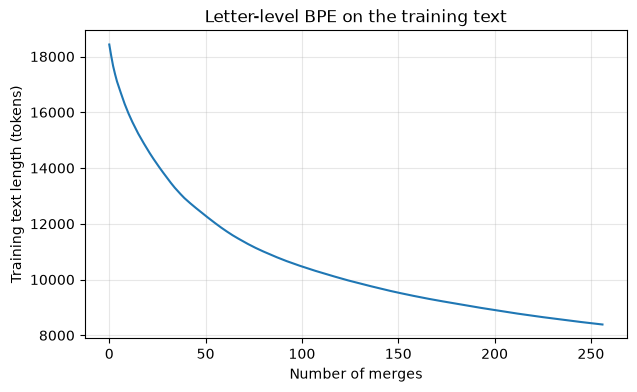

First 20 merges:
  1. ' ' + 't'
  2. 'h' + 'e'
  3. ' ' + 'a'
  4. 'i' + 'n'
  5. ' ' + 'h'
  6. ' ' + 's'
  7. ' ' + 'w'
  8. ' ' + 'o'
  9. ' t' + 'he'
 10. 'r' + 'e'
 11. 'o' + 'u'
 12. 'i' + 't'
 13. 'i' + 's'
 14. ' ' + 'm'
 15. 'e' + 'd'
 16. ' ' + 'b'
 17. 'a' + 't'
 18. 'n' + 'd'
 19. ' ' + 'p'
 20. 'in' + 'g'

Longest tokens: [' Gisburn', ' picture', ' Stroud', 'isburn', ' paint', ' Strou', ' about', ' could', ' that', ' with', ' have', 'ation', ' pict', ' been', ' said']


In [11]:
plt.figure(figsize=(7, 4))
plt.plot(range(len(char_bpe.lengths)), char_bpe.lengths)
plt.xlabel("Number of merges")
plt.ylabel("Training text length (tokens)")
plt.title("Letter-level BPE on the training text")
plt.grid(True, alpha=0.3)
plt.show()

print("First 20 merges:")
for k, m in enumerate(char_bpe.merge_strings()[:20], start=1):
    print(f"{k:3d}. {m}")

print("\nLongest tokens:", sorted(char_bpe.vocab, key=len, reverse=True)[:15])

The 62 distinct characters of the training text are the base vocabulary, and after 256 merges the 18,431 characters become **8,388 tokens** (2.2 characters per token), as in the reference. The curve falls steeply at first and then flattens: each merge shortens the text by the number of occurrences of the merged pair, and BPE always takes the most frequent pair first, so the first merges (` t`, `he`, ` a`, `in`, ...) save hundreds of tokens each, while the late ones only merge pairs that occur a few dozen times. The first merges are frequent English bigrams with a leading space, and they quickly build whole words: ` t` + `he` = ` the` is merge 9. The longest tokens are frequent words of this story with their leading space (` Gisburn`, ` picture`, ` Stroud`, ...), which shows that the merges reflect the training text: in another text these would be rare.

**Round trip and unknown characters.**

In [12]:
held_char_ids = char_bpe.encode(held_text)
print("Held-out text:", len(held_text), "characters ->", len(held_char_ids), "tokens")
print("decode(encode(held_text)) == held_text:", char_bpe.decode(held_char_ids) == held_text)

for word in ["Łódź", "北京"]:
    try:
        char_bpe.encode(word)
    except KeyError as e:
        print(f"encode({word!r}) fails: KeyError {e}, this character is not in the base vocabulary")

Held-out text: 2048 characters -> 906 tokens
decode(encode(held_text)) == held_text: True
encode('Łódź') fails: KeyError 'Ł', this character is not in the base vocabulary
encode('北京') fails: KeyError '北', this character is not in the base vocabulary


Unlike the word tokenizer of Task 3.1, the BPE tokenizer is **lossless** on the held-out text: the chunks keep every character, including spaces and newlines (a space is part of the following word, runs of whitespace are their own chunks), and decoding just concatenates the token strings. It also has no `<|unk|>` problem for new English **words**: an unseen word is simply split into smaller known pieces, down to single letters.

It fails, however, for new **characters**: `Łódź` raises a `KeyError` at `Ł`, and the Chinese word at its first character, because the base vocabulary only contains the 62 characters that occur in the (purely ASCII) training text. This is the OOV problem of Task 3.2 again, one level lower: there are about 150,000 Unicode characters, and no training text contains all of them. Task 3.4 solves it by using bytes as the base vocabulary.

## 3.4 From letters to bytes: byte-level BPE

> - Replace the base vocabulary by the 256 UTF-8 byte values (merged tokens get IDs 256, 257, …; ties broken by the smaller pair of IDs); `decode` concatenates the bytes and then decodes UTF-8. Train on the same chunks with 256 merges (vocabulary size 512). Show that on this ASCII text the merges are the same as in Task 3.3, and that the round trip now works for any string, including `Łódź` and Chinese.
> - Train your byte-level BPE with about 60 merges on a short text full of multi-byte characters, for example a few Polish and Chinese sentences of your choice. Classify each new token as ASCII, whole multi-byte character(s), part of one character, or crossing a character boundary, and show which characters end up as one token and which stay split into bytes. Relate what you see to Lecture 3, Q&A, Question 1.
> - Compare your tokenizer with GPT-2's (`tiktoken`) on the held-out text and on a short Polish text: bytes per token, and whether `decode(encode(s)) == s`. Explain the difference between the two languages. Reference: GPT-2 encodes the whole text in 5145 tokens; on the held-out text your tokenizer gives about 2.3 bytes per token and GPT-2 about 3.8.
> - Find a GPT-2 token whose bytes are not valid UTF-8 on their own, and show what decoding token by token does to it.
> - Train on the training text as one chunk, without the split, and compare the learned merges and the compression. *(optional)*

**Byte-level BPE.** The class is the same as `CharBPE` with one change: a chunk is turned into its UTF-8 bytes (`list(chunk.encode("utf-8"))`), and the base vocabulary is the fixed set of the 256 byte values, so merged tokens get IDs 256, 257, .... `vocab[i]` is now the `bytes` object of token `i`; `decode` joins the bytes of all tokens first and decodes UTF-8 only once at the end.

In [13]:
class ByteBPE:
    """BPE whose base vocabulary is the 256 byte values."""

    def __init__(self, chunks, num_merges):
        base_chunks = [list(c.encode("utf-8")) for c in chunks]
        self.merges, self.lengths = train_bpe(base_chunks, num_merges, first_id=256)
        self.vocab = [bytes([b]) for b in range(256)]       # vocab[i] = bytes of token i
        for (a, b) in self.merges:
            self.vocab.append(self.vocab[a] + self.vocab[b])

    def encode(self, s):
        ids = []
        for chunk in re.findall(CHUNK_PATTERN, s):
            ids += encode_chunk(list(chunk.encode("utf-8")), self.merges)
        return ids

    def decode(self, ids):
        return b"".join(self.vocab[i] for i in ids).decode("utf-8")


byte_bpe = ByteBPE(train_chunks, num_merges=256)
print("Vocabulary size:", len(byte_bpe.vocab))
print(f"Training text: {len(train_text.encode('utf-8')):,} bytes -> {byte_bpe.lengths[-1]:,} tokens")

# The merges as strings, in merge order, for both tokenizers
char_merged = [char_bpe.vocab[i] for i in char_bpe.merges.values()]
byte_merged = [byte_bpe.vocab[i].decode("utf-8") for i in byte_bpe.merges.values()]
print("Same merges as the letter-level BPE (in the same order):", char_merged == byte_merged)
print("Same training length after every merge:", char_bpe.lengths == byte_bpe.lengths)

Vocabulary size: 512
Training text: 18,431 bytes -> 8,388 tokens
Same merges as the letter-level BPE (in the same order): True
Same training length after every merge: True


On this text the byte-level BPE learns **exactly the same 256 merges in the same order** as the letter-level BPE, and the training text has the same length after every merge. The reason: the text is pure ASCII, and for ASCII characters UTF-8 uses one byte whose value equals the code point. So every chunk is the same sequence of units in both tokenizers (only the IDs are shifted), the pair counts are the same, and the tie-breaking "smaller pair of IDs" orders the pairs in the same way, because both the sorted characters and the byte values follow the code-point order. The only difference is the 194 base tokens (non-ASCII and unused bytes) that never occur in the training text.

**The round trip now works for any string.**

In [14]:
tests = [held_text, "Łódź", "北京大学", "Zażółć gęślą jaźń", "naïve café 😀", "tabs\tand\nnewlines  "]
for s in tests:
    ids = byte_bpe.encode(s)
    label = "held-out text" if s is held_text else repr(s)
    print(f"{label:24} {len(s.encode('utf-8')):5d} bytes -> {len(ids):4d} tokens, round trip OK: {byte_bpe.decode(ids) == s}")

print("\n'Łódź' ->", byte_bpe.encode("Łódź"), "=", [byte_bpe.vocab[i] for i in byte_bpe.encode("Łódź")])

held-out text             2048 bytes ->  906 tokens, round trip OK: True
'Łódź'                       7 bytes ->    7 tokens, round trip OK: True
'北京大学'                      12 bytes ->   12 tokens, round trip OK: True
'Zażółć gęślą jaźń'         26 bytes ->   24 tokens, round trip OK: True
'naïve café 😀'              17 bytes ->   15 tokens, round trip OK: True
'tabs\tand\nnewlines  '     19 bytes ->   14 tokens, round trip OK: True

'Łódź' -> [197, 129, 195, 179, 100, 197, 186] = [b'\xc5', b'\x81', b'\xc3', b'\xb3', b'd', b'\xc5', b'\xba']


Every string now survives `decode(encode(s))`, including Polish, Chinese and an emoji. Since all 256 byte values are in the base vocabulary, every UTF-8 text can be encoded, and merges only add shortcuts. Characters that never occurred in training are not an error any more; they are just expensive: `Łódź` is 4 characters but 7 bytes, and since no merge involves its non-ASCII bytes it becomes 7 tokens (only `d` is a "real" character token).

**Training on a text full of multi-byte characters.** We take a few Polish and Chinese sentences (Polish letters such as `ą`, `ł`, `ż` take 2 bytes in UTF-8, Chinese characters 3 bytes) and train with 60 merges. Each new token is then classified by its bytes (see the table of byte roles in Materials 3.4: `00–7F` ASCII, `80–BF` continuation byte, `C2–F4` lead byte):

- **ASCII**: all bytes below `0x80`;
- **whole character(s)**: not ASCII, but decodes with strict UTF-8, i.e. consists of complete characters (possibly together with ASCII ones, like ` ł`);
- **part of one character**: does not decode, and contains no ASCII byte and no lead byte except possibly at its start, so all its bytes belong to a single character;
- **crossing a character boundary**: does not decode, and contains bytes of two different characters (an ASCII byte, or a lead byte after the first position, next to an incomplete character).

In [15]:
multi_text = (
    "Zażółć gęślą jaźń. Wrocław leży nad Odrą, a Łódź w środku Polski. "
    "Źródło wiedzy jest w książkach, więc często czytamy książki. "
    "我喜欢学习语言模型。中文没有空格，所以整个句子是一个块。我们今天学习中文和波兰语。"
)
multi_chunks = re.findall(CHUNK_PATTERN, multi_text)
print(f"{len(multi_text)} characters, {len(multi_text.encode('utf-8'))} bytes, {len(multi_chunks)} chunks")
print("Chunks:", multi_chunks)


def classify(token):
    """Classify the bytes of a token by how they relate to UTF-8 characters."""
    if token.isascii():
        return "ASCII"
    try:
        token.decode("utf-8")
        return "whole character(s)"
    except UnicodeDecodeError:
        pass
    other_char_inside = any(b < 0x80 or b >= 0xC0 for b in token[1:])  # ASCII or lead byte after the start
    if token[0] < 0x80 or other_char_inside:
        return "crossing a boundary"
    return "part of one character"


multi_bpe = ByteBPE(multi_chunks, num_merges=60)
print(f"\n{'ID':>4}  {'bytes (hex)':<20} {'shown as':<10} class")
for i in multi_bpe.merges.values():
    tok = multi_bpe.vocab[i]
    print(f"{i:>4}  {tok.hex(' '):<20} {tok.decode('utf-8', errors='replace')!r:<10} {classify(tok)}")

print("\nCount per class:", dict(Counter(classify(multi_bpe.vocab[i]) for i in multi_bpe.merges.values())))

168 characters, 275 bytes, 34 chunks
Chunks: ['Zażółć', ' gęślą', ' jaźń', '.', ' Wrocław', ' leży', ' nad', ' Odrą', ',', ' a', ' Łódź', ' w', ' środku', ' Polski', '.', ' Źródło', ' wiedzy', ' jest', ' w', ' książkach', ',', ' więc', ' często', ' czytamy', ' książki', '.', ' 我喜欢学习语言模型', '。', '中文没有空格', '，', '所以整个句子是一个块', '。', '我们今天学习中文和波兰语', '。']

  ID  bytes (hex)          shown as   class
 256  e4 b8                '�'        part of one character
 257  20 77                ' w'       ASCII
 258  c4 85                'ą'        whole character(s)
 259  c5 bc                'ż'        whole character(s)
 260  20 c5                ' �'       crossing a boundary
 261  80 82                '��'       part of one character
 262  c3 b3                'ó'        whole character(s)
 263  c4 99                'ę'        whole character(s)
 264  c5 82                'ł'        whole character(s)
 265  e3 80 82             '。'        whole character(s)
 266  e4 bb                '�'        par

Now, for every non-ASCII character of the text, we encode it **on its own** and count its tokens: 1 token means its bytes were merged into one token, more tokens mean it stays split into bytes (or into a part and a byte).

In [16]:
non_ascii = sorted({ch for ch in multi_text if not ch.isascii()})
n_tokens = {ch: len(multi_bpe.encode(ch)) for ch in non_ascii}
char_counts = Counter(multi_text)

one_token = [ch for ch in non_ascii if n_tokens[ch] == 1]
still_split = [ch for ch in non_ascii if n_tokens[ch] > 1]
print("Format: character(occurrences in the text, tokens)")
print("One token:      ", " ".join(f"{ch}({char_counts[ch]}x)" for ch in one_token))
print("Split in bytes: ", " ".join(f"{ch}({char_counts[ch]}x, {n_tokens[ch]} tok)" for ch in still_split))

Format: character(occurrences in the text, tokens)
One token:       ó(3x) ą(4x) ę(3x) ł(3x) ź(2x) ż(4x) 。(3x) 我(2x) 语(2x)
Split in bytes:  ć(1x, 2 tok) Ł(1x, 2 tok) ń(1x, 2 tok) ś(2x, 2 tok) Ź(1x, 2 tok) 一(1x, 2 tok) 个(2x, 2 tok) 中(2x, 2 tok) 习(2x, 2 tok) 今(1x, 2 tok) 以(1x, 2 tok) 们(1x, 2 tok) 兰(1x, 3 tok) 句(1x, 3 tok) 和(1x, 3 tok) 喜(1x, 3 tok) 块(1x, 3 tok) 型(1x, 3 tok) 天(1x, 3 tok) 子(1x, 2 tok) 学(2x, 2 tok) 所(1x, 3 tok) 整(1x, 3 tok) 文(2x, 2 tok) 是(1x, 3 tok) 有(1x, 3 tok) 格(1x, 3 tok) 模(1x, 3 tok) 欢(1x, 3 tok) 没(1x, 3 tok) 波(1x, 3 tok) 空(1x, 3 tok) 言(1x, 3 tok) ，(1x, 3 tok)


The 60 merges give all four classes, exactly as described in Lecture 3, Q&A, Question 1:

1. **At the start every byte is a token**, so a Polish letter is 2 tokens and a Chinese character 3 tokens before any merge.
2. **Merges are chosen by frequency only.** The bytes of the Polish letters that occur several times (`ą`, `ż`, `ó`, `ę`, `ł`, `ź`) and of `我`, `语` and `。` were merged into whole-character tokens. Letters that occur once or twice (`ć`, `ń`, `ś`, `Ł`, `Ź`) and most Chinese characters stay split into 2–3 tokens. There are also tokens that are **part of one character**: the first two bytes `e4 b8` start `中`, `个` and `一`, so this prefix is more frequent than any of the three characters and is merged first (it is the very first merge).
3. **Merges ignore character boundaries inside a chunk.** Tokens such as `20 c5` (a space plus the lead byte of `ż`/`ł`/`ś`), `a6 e4` (the last byte of `学` plus the first byte of `习`) or `e4 b8 ad e6` (`中` plus the first byte of `文`) **cross a character boundary**: they are not valid UTF-8 on their own. Some of them are later merged further into whole multi-character tokens (`中` + `e6` → ... → `中文`, and `学习`), so `学`, `习`, `中` and `文` are covered by one token inside these words although each of them alone is still split into 2 tokens.
4. **Merges never cross chunk boundaries.** Polish letters count as `\w`, so they stay inside their words, and Polish tokens look like word pieces (` książ`, `sią`). Chinese has no spaces, so each sentence up to a punctuation mark is a single chunk, and merges inside it freely cross from one character to the next, building multi-character tokens such as `中文` and `学习`.

**Comparison with GPT-2.** We compare our byte-level BPE (256 merges on the English training text) with GPT-2's tokenizer (50,000 merges, trained on a large web corpus) on the held-out text and on a short Polish text. Bytes per token $M/N$ measure how much text one token carries on average.

In [17]:
gpt2 = tiktoken.get_encoding("gpt2")
print("GPT-2 tokens for the whole text:", len(gpt2.encode(text)))

polish_text = ("Wczoraj wieczorem poszliśmy z przyjaciółmi na spacer brzegiem Odry. "
               "Żółte liście szeleściły pod stopami, a w oddali słychać było dźwięk tramwaju.")

print(f"\n{'text':<10} {'tokenizer':<12} {'bytes':>6} {'tokens':>7} {'bytes/token':>12}  round trip")
for name, s in [("held-out", held_text), ("Polish", polish_text)]:
    M = len(s.encode("utf-8"))
    for tok_name, enc, dec in [("our BPE", byte_bpe.encode, byte_bpe.decode),
                               ("GPT-2", gpt2.encode, gpt2.decode)]:
        ids = enc(s)
        print(f"{name:<10} {tok_name:<12} {M:>6} {len(ids):>7} {M / len(ids):>12.2f}  {dec(ids) == s}")

GPT-2 tokens for the whole text: 5145

text       tokenizer     bytes  tokens  bytes/token  round trip
held-out   our BPE        2048     906         2.26  True
held-out   GPT-2          2048     534         3.84  True
Polish     our BPE         159     125         1.27  True
Polish     GPT-2           159      78         2.04  True


Both tokenizers are lossless on both texts, since both are byte-level. On the English held-out text our tokenizer gives **2.26 bytes per token** and GPT-2 **3.84**, as in the reference: with 50,000 merges GPT-2 has whole words (with their leading space) for almost all common English words, while our 256 merges only cover the most frequent words and word pieces of one short story.

On the Polish text both are much worse: our tokenizer gets about 1.3 bytes per token (barely better than raw bytes, because none of its merges involves Polish letters and only a few English letter pairs apply), and GPT-2 only about 2.0 bytes per token, half of its English rate. The reason is the same for both: BPE gives long tokens to the frequent sequences **of its training data**, which is mostly English. Polish words are split into short pieces, and the Polish letters take 2 bytes each and are often not even merged into one token. The same sentence therefore costs a Polish user about twice as many tokens: less text fits into the context window and every word is more expensive to process.

**A GPT-2 token that is not valid UTF-8.** GPT-2 encodes ` Łódź` (Materials 3.4) with tokens that contain only one byte of a 2-byte character. Decoding such a token on its own is impossible:

In [18]:
s = " Łódź"
ids = gpt2.encode(s)
print(f"{'ID':>6}  {'bytes':<10} valid UTF-8 on its own?  decoded alone")
for t in ids:
    b = gpt2.decode_single_token_bytes(t)
    try:
        b.decode("utf-8")
        valid = True
    except UnicodeDecodeError:
        valid = False
    print(f"{t:>6}  {b.hex(' '):<10} {str(valid):<24} {gpt2.decode([t])!r}")

token_by_token = "".join(gpt2.decode([t]) for t in ids)
print("\nDecoding token by token and joining:", repr(token_by_token), "== s:", token_by_token == s)
print("Joining the bytes, then decoding:   ", repr(gpt2.decode(ids)), "== s:", gpt2.decode(ids) == s)

    ID  bytes      valid UTF-8 on its own?  decoded alone
 25370  20 c5      False                    ' �'
   223  81         False                    '�'
 10205  c3 b3      True                     'ó'
    67  64         True                     'd'
   129  c5         False                    '�'
   118  ba         False                    '�'

Decoding token by token and joining: ' ��ód��' == s: False
Joining the bytes, then decoding:    ' Łódź' == s: True


Token 129 is the single byte `C5`, the **lead byte** of `ź` (`C5 BA`), and token 118 is its continuation byte `BA`; token 25370 is a space plus the lead byte of `Ł`. None of these is a complete UTF-8 character, so `gpt2.decode([t])` for a single token cannot produce a character and inserts the replacement character `�` (tiktoken decodes with `errors="replace"`). Joining these per-token strings turns `Łódź` into `��ód��`: the bytes are lost forever. Decoding the whole sequence at once first joins the bytes (`C5` + `BA` = `ź`) and gives the correct text. This is why a streaming chatbot must buffer incomplete bytes instead of printing every token as soon as it is generated.

**Training without the chunk split** *(optional)*. We train the same byte-level BPE on the training text as **one** chunk, so merges may cross word boundaries.

In [19]:
one_chunk_bpe = ByteBPE([train_text], num_merges=256)

print("First 25 merges, chunks:   ", [byte_bpe.vocab[i].decode() for i in list(byte_bpe.merges.values())[:25]])
print("First 25 merges, one chunk:", [one_chunk_bpe.vocab[i].decode() for i in list(one_chunk_bpe.merges.values())[:25]])
print("\nLongest tokens, chunks:   ", sorted((t.decode() for t in byte_bpe.vocab[256:]), key=len, reverse=True)[:10])
print("Longest tokens, one chunk:", sorted((t.decode() for t in one_chunk_bpe.vocab[256:]), key=len, reverse=True)[:10])
multi_word = [t.decode() for t in one_chunk_bpe.vocab[256:] if " " in t.decode().strip()]
print(f"\nOne-chunk tokens spanning two words: {len(multi_word)}, e.g. {multi_word[:12]}")

held_one = encode_chunk(list(held_text.encode("utf-8")), one_chunk_bpe.merges)
print(f"\nTraining text: {byte_bpe.lengths[-1]} tokens with chunks, {one_chunk_bpe.lengths[-1]} as one chunk")
print(f"Held-out text: {len(byte_bpe.encode(held_text))} tokens with chunks, {len(held_one)} as one chunk")

First 25 merges, chunks:    [' t', 'he', ' a', 'in', ' h', ' s', ' w', ' o', ' the', 're', 'ou', 'it', 'is', ' m', 'ed', ' b', 'at', 'nd', ' p', 'ing', 'as', 'en', ' f', ' d', 'er']
First 25 merges, one chunk: ['e ', ' t', 'd ', 't ', 'in', 's ', 'he ', ', ', 'er', 'ha', 'ou', 'on', 'an', 'en', ' the ', 'y ', '. ', 'it', 'ing', 'ed ', 'o ', 'hi', 'of', 'I ', 're']

Longest tokens, chunks:    [' Gisburn', ' picture', ' Stroud', 'isburn', ' paint', ' Strou', ' about', ' could', ' that', ' with']
Longest tokens, one chunk: ['of the ', 'Gisburn', 'in the ', 'he was ', 'at the ', ' that ', 'Gisbur', ', and ', ' the t', 'ed to ']

One-chunk tokens spanning two words: 18, e.g. ['e t', 'of the ', 'e to ', 'e of ', ', I ', '. . ', ', and ', 'in the ', ' the t', 'ed to ', 'I had ', 'e the ']

Training text: 8388 tokens with chunks, 8406 as one chunk
Held-out text: 906 tokens with chunks, 917 as one chunk


Without the split, the space can be merged with the **previous** word as well as the next one, so the first merges are different: `e ` (an `e` at the end of a word plus the following space), `d `, `t `, `s `, `, ` and `. ` are among the earliest. Later the tokenizer learns whole phrases such as `of the `, `in the `, `he was `, which a chunked tokenizer can never produce. The compression is nevertheless almost the same and even slightly worse: 8,406 instead of 8,388 tokens on the training text and 917 instead of 906 on the held-out text. The merges are spread over many variants of the same word (` the`, ` the `, `the `, ...) and over phrases, instead of being spent on new words. So splitting into chunks costs nothing in compression, but gives a cleaner vocabulary: tokens are words or word pieces with one leading space, instead of arbitrary pieces of phrases that depend on the punctuation around a word.

## 3.5 Comparing tokenizers with bits per byte

> - Fit the add-$\alpha$ bigram model of List 1, Task 2.3, to token IDs instead of characters, for three tokenizers: bytes ($V = 256$) and your byte-level BPE with $V = 512$ and $V = 1024$ (default $\alpha = 0.1$). Fit on the first 90% and report, for each tokenizer, the per-token perplexity of the held-out text and its bits per byte $\mathrm{BPB} = N\bar\ell/(M \ln 2)$: $N$ held-out tokens with mean negative log-likelihood $\bar\ell$ (in nats), $M$ UTF-8 bytes of the held-out text.
> - Explain why the two measures rank the tokenizers in opposite orders. Reference: perplexity about 11.5, 87 and 290; BPB about 3.53, 2.85 and 2.83.

**Setup.**

- The three tokenizers are one byte-level BPE trained with 768 merges ($V = 1024$). Training to vocabulary size $V$ gives exactly its first $V - 256$ merges, because each merge depends only on the earlier ones, so we keep the merges with IDs below $V$. With $V = 256$ there are no merges and every byte is a token.
- The bigram model is the one from List 1: count the pairs with `torch.bincount`, add $\alpha = 0.1$ to every cell of the $V \times V$ table and normalise the rows.
- Every held-out token is scored, including the first one, whose context is the last training token. All tokenizers are evaluated on the same held-out text with the same $M$.
- Perplexity $= \exp(\bar\ell)$, BPB $= N\bar\ell / (M\ln 2)$ = total NLL in bits divided by the number of bytes.

In [20]:
bpe_1024 = ByteBPE(train_chunks, num_merges=768)
ALPHA = 0.1
M = len(held_text.encode("utf-8"))


def encode_with(merges, s):
    """Byte-level BPE encoding with a given set of merges."""
    ids = []
    for chunk in re.findall(CHUNK_PATTERN, s):
        ids += encode_chunk(list(chunk.encode("utf-8")), merges)
    return ids


print(f"Held-out text: M = {M} bytes\n")
print(f"{'V':>5} {'merges':>7} {'N tokens':>9} {'bytes/token':>12} {'mean NLL':>9} {'perplexity':>11} {'BPB':>7}")
for V in [256, 512, 1024]:
    merges = {pair: i for pair, i in bpe_1024.merges.items() if i < V}
    train_ids = torch.tensor(encode_with(merges, train_text))
    held_ids = torch.tensor(encode_with(merges, held_text))

    # add-alpha bigram model fitted on the training tokens
    counts = torch.bincount(train_ids[:-1] * V + train_ids[1:], minlength=V * V).view(V, V).double()
    P = (counts + ALPHA) / (counts + ALPHA).sum(dim=1, keepdim=True)

    # score every held-out token; the first one is predicted from the last training token
    seq = torch.cat([train_ids[-1:], held_ids])
    nll = -torch.log(P[seq[:-1], seq[1:]])
    N, mean_nll = len(held_ids), nll.mean().item()
    bpb = N * mean_nll / (M * math.log(2))
    print(f"{V:>5} {len(merges):>7} {N:>9} {M / N:>12.2f} {mean_nll:>9.3f} {math.exp(mean_nll):>11.1f} {bpb:>7.3f}")

Held-out text: M = 2048 bytes

    V  merges  N tokens  bytes/token  mean NLL  perplexity     BPB
  256       0      2048         1.00     2.445        11.5   3.528
  512     256       906         2.26     4.470        87.4   2.853
 1024     768       709         2.89     5.669       289.9   2.832


The results match the reference: perplexity **11.5, 87 and 290**, BPB **3.53, 2.85 and 2.83**. By perplexity the byte tokenizer is by far the best, by BPB it is the worst, and $V = 1024$ is the best.

**Why the two measures disagree.** Perplexity is measured **per token**, and the tokens of the three tokenizers are different units. A byte-level model only has to guess the next byte, one of a few dozen likely characters, while the $V = 1024$ model has to guess the next token, which is on average a whole 2.9-byte word piece out of 1024: each single prediction is much harder, so the per-token perplexity grows with $V$. But the larger tokenizer needs far fewer predictions for the same text (709 instead of 2048). BPB divides the **total** NLL by the number of bytes, which is the same for all tokenizers, so it measures how well the whole system (tokenizer + model) predicts the **same text**. With BPE, a bigram model conditions on the previous token, i.e. on 2–3 previous bytes instead of one, so it sees more context and spends fewer bits on the whole text, even though every single token is harder to guess. Only BPB (or the total NLL) can compare models with different tokenizers.

The gain from 512 to 1024 is small (2.85 → 2.83): the bigram table has $V^2 \approx 10^6$ cells but the training text only about 6,400 tokens, so most pairs are never seen and their probability comes from the smoothing $\alpha$ alone; the better context is almost cancelled by the sparser statistics.

## 3.6 Tokenization consequences *(optional)*

> With `tiktoken`, show how GPT-2 splits `strawberry` with and without a leading space, numbers such as `12345` and `1234 + 5678`, and repeated spaces. Relate what you see to the difficulties LLMs have with counting letters and with arithmetic.

In [21]:
def show_tokens(s):
    ids = gpt2.encode(s)
    pieces = [gpt2.decode_single_token_bytes(t).decode("utf-8") for t in ids]
    print(f"{s!r:22} {len(ids):2d} tokens: {pieces}  IDs: {ids}")


for s in ["strawberry", " strawberry", "Strawberry", "12345", "123456789", "1234 + 5678", "6912",
          "1000", "1001", "a b", "a  b", "a     b", "    indented code"]:
    show_tokens(s)

'strawberry'            3 tokens: ['st', 'raw', 'berry']  IDs: [301, 1831, 8396]
' strawberry'           1 tokens: [' strawberry']  IDs: [41236]
'Strawberry'            3 tokens: ['St', 'raw', 'berry']  IDs: [1273, 1831, 8396]
'12345'                 2 tokens: ['123', '45']  IDs: [10163, 2231]
'123456789'             4 tokens: ['123', '45', '67', '89']  IDs: [10163, 2231, 3134, 4531]
'1234 + 5678'           5 tokens: ['12', '34', ' +', ' 5', '678']  IDs: [1065, 2682, 1343, 642, 30924]
'6912'                  2 tokens: ['69', '12']  IDs: [3388, 1065]
'1000'                  1 tokens: ['1000']  IDs: [12825]
'1001'                  1 tokens: ['1001']  IDs: [47705]
'a b'                   2 tokens: ['a', ' b']  IDs: [64, 275]
'a  b'                  3 tokens: ['a', ' ', ' b']  IDs: [64, 220, 275]
'a     b'               6 tokens: ['a', ' ', ' ', ' ', ' ', ' b']  IDs: [64, 220, 220, 220, 220, 275]
'    indented code'     6 tokens: [' ', ' ', ' ', ' ind', 'ented', ' code']  IDs: [220, 220, 2

**Letters.** `strawberry` without a space is three tokens (`st`, `raw`, `berry`), with a leading space it is a **single** token (ID 41236), and `Strawberry` is again different (`St`, `raw`, `berry`). The model receives these IDs, not the ten letters: the three `r`s are hidden inside `raw` and `berry`, or inside one opaque ID. To answer "how many r's are in strawberry" it has to know the spelling of every token (which is not visible in an ID) and add the counts across token boundaries; and the same word reaches the model as different token sequences depending on the space and capitalisation in front of it. This knowledge has to be learned indirectly from data, which is why LLMs often miscount letters.

**Numbers.** `12345` is split into `123` + `45`, and long numbers into chunks whose boundaries depend on which digit strings happen to be frequent in the training data: `1000` and `1001` are single tokens, while `1234` is `12` + `34`. In `1234 + 5678` the space is attached to the first digit (` 5` + `678`), so the second number is split 1+3 while the first is split 2+2 and the sum `6912` again 2+2 (`69` + `12`). The units, tens and hundreds columns, on which written addition works, do not line up with the token boundaries, and the same number can be tokenized in different ways in different contexts. The model has to learn arithmetic over an irregular, number-dependent split, which makes it harder (newer tokenizers split numbers into single digits or groups of three for exactly this reason).

**Spaces.** A leading space is part of the token, so `strawberry` and ` strawberry` are unrelated IDs. With repeated spaces, the last space stays attached to the following word and every other space becomes its own token (ID 220): `a     b` is `a`, four single-space tokens and ` b`, and 4-space code indentation costs 3 extra tokens. The same content with different whitespace therefore gives a different token sequence, and code with indentation is expensive for GPT-2 (newer tokenizers added tokens for runs of spaces).

## Checkpoint (Lab 3)

> Your byte-level BPE (Task 3.4) gives `decode(encode(s)) == s` for every string in Materials, Appendix B (empty text, leading and repeated spaces, newlines, Polish, Japanese, an emoji with a skin-tone modifier, and the literal text `<|endoftext|>`).

The check is run with the byte-level BPE of Task 3.4 (256 merges on the training text). Our tokenizer has no special tokens, so the literal text `<|endoftext|>` is encoded as ordinary characters.

In [22]:
def check_roundtrip(encode, decode):
    strings = ["", " leading space", "repeated   spaces",
               "two\nlines\n\n", "Zażółć gęślą jaźń",
               "猫が好きです", "👍🏽 thumbs up", "<|endoftext|>"]
    for s in strings:
        assert decode(encode(s)) == s, f"round trip fails for {s!r}"
    print("Checkpoint Lab 3 passed")


check_roundtrip(byte_bpe.encode, byte_bpe.decode)

Checkpoint Lab 3 passed
